In [8]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8')
%matplotlib inline

In [9]:
#Load data
df = pd.read_csv('C:/ANTIGRAVITY/cutomerchurn/data/archive.zip')
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
#Basic info
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nChurn distribution:\n", df['Churn'].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


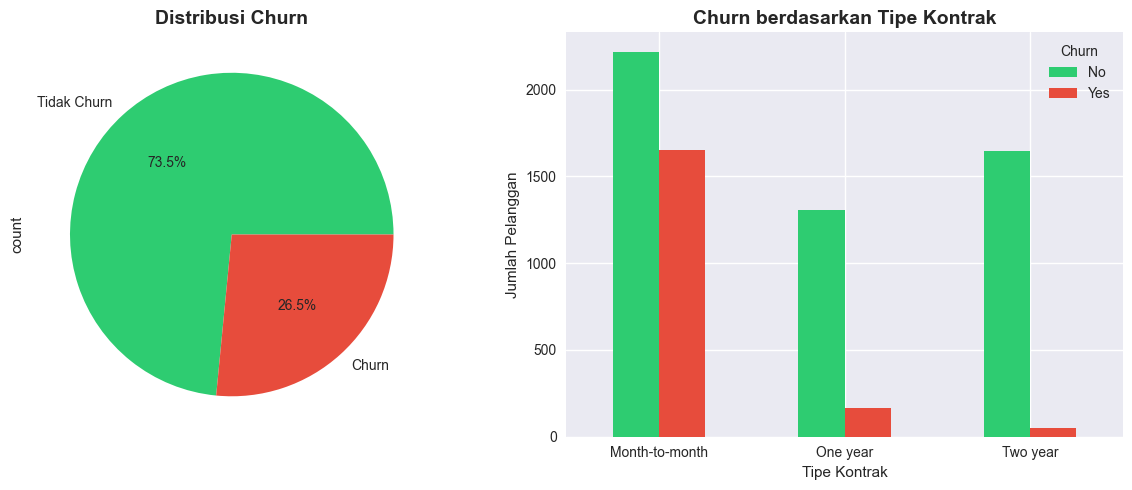

In [11]:
#Churn distribution chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart
df['Churn'].value_counts().plot.pie(
    autopct='%1.1f%%', ax=ax1,
    colors=['#2ecc71', '#e74c3c'],
    labels=['Tidak Churn', 'Churn']
)
ax1.set_title('Distribusi Churn', fontsize=14, fontweight='bold')

# Bar chart by contract type
churn_by_contract = df.groupby(['Contract', 'Churn']).size().unstack()
churn_by_contract.plot(kind='bar', ax=ax2, color=['#2ecc71', '#e74c3c'])
ax2.set_title('Churn berdasarkan Tipe Kontrak', fontsize=14, fontweight='bold')
ax2.set_xlabel('Tipe Kontrak')
ax2.set_ylabel('Jumlah Pelanggan')
ax2.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('../outputs/figures/churn_overview.png', dpi=150, bbox_inches='tight')
plt.show()

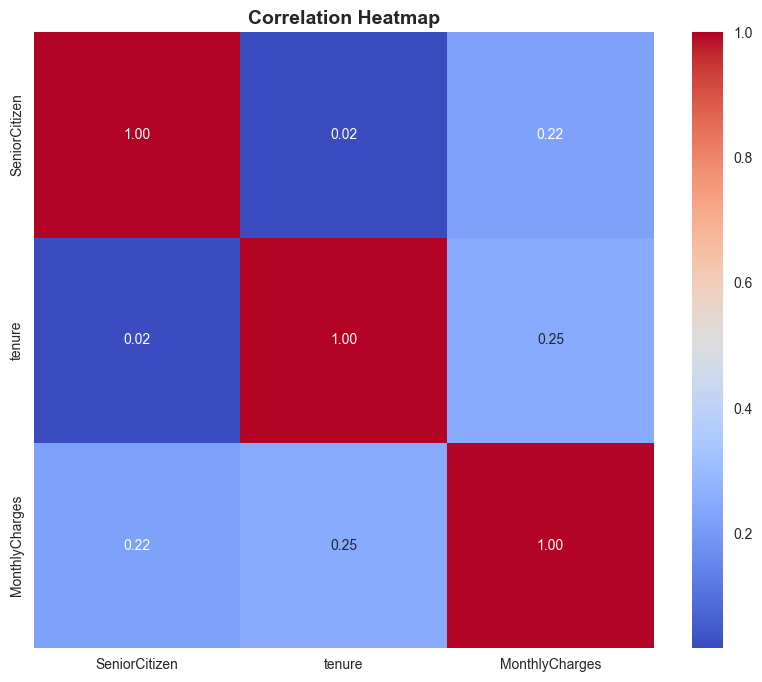

In [12]:
#Numerical features correlation
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.savefig('../outputs/figures/correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

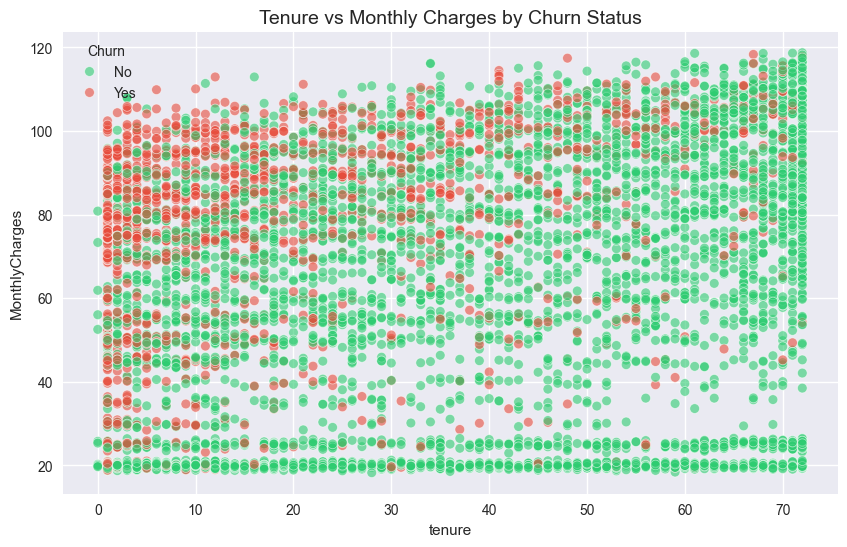

In [13]:
#Tenure vs Monthly Charges
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='tenure', y='MonthlyCharges', hue='Churn',
                palette={'Yes': '#e74c3c', 'No': '#2ecc71'}, alpha=0.6)
plt.title('Tenure vs Monthly Charges by Churn Status', fontsize=14)
plt.savefig('../outputs/figures/tenure_charges_scatter.png', dpi=150, bbox_inches='tight')
plt.show()